# Work Package 1 (WP1): Business & Clinical Case
## Starting Discharge Planning on Day 1 to Free Blocked Hospital Beds

**Course:** Data analysis (UPM)
**Team:** Andrea Brugnera, Jin fa Zheng
**Who we are talking to:** the Hospital Board, Medical Directors, the Director of Patient Flow and the Head of Case Management

---

### The whole story in 4 points

1. **The problem (Tasks 1 & 2).** US hospitals are paid a **fixed amount per admission** for the patient's condition (DRG), **not per day**. Days beyond the normal stay for that condition (**excess bed-days**) bring **no extra payment**, cost nursing time and supplies, and hold a bed that an emergency or surgical patient needs.
   * **Where the days go:** three quarters of excess bed-days are in patients who leave for a **nursing home (SNF)**, **home health care**, rehab or hospice. This is consistent with post-hospital care being arranged too late.
   * **The decision:** **at admission (Day 1)**, flag patients likely to overstay so **case managers start arranging their post-hospital care on Day 1**, not at the end of the stay.
   * **Who owns it:** the **Director of Patient Flow** and the **Head of Case Management** of the **Finger Lakes Health System** (17 hospitals around Rochester, NY; about 94,000 adult medical-surgical stays a year).

2. **KPI and baseline (Task 3).** **Excess bed-days per 100 admissions**: days beyond the typical stay (P75) for the same diagnosis and severity in New York State in 2017. The ruler is frozen for the whole project.
   * **2023 baseline: 192.8 excess bed-days per 100 admissions** (181,460 excess bed-days; 24.4% of stays prolonged).

3. **The cost of doing nothing (Task 5).**
   * Like for like, the KPI rose **+78%**, from 108.1 in 2017 to 192.5 in 2023. Finger Lakes is now the **highest of the 8 New York regions** (rest of the state: 129.9).
   * Not every excess day is avoidable: even at its own 2017 rate the system would have about 101,700. The **addressable gap is about 79,700 bed-days a year: 218 beds every day**, or room for about 11,900 more admissions.

4. **What it returns (Task 5, the reviewer's cost scenario).** Each bed-day saved has two kinds of value:
   * **Cash:** the variable cost of the day. We use **16%** of a $2,344 day = **$375** ([Roberts et al., JAMA 1999](https://jamanetwork.com/journals/jama/fullarticle/188795): 84% of hospital costs are fixed).
   * **Capacity:** a freed bed refilled by another paid admission is worth about **$2,359 per bed-day** (payment minus that admission's variable cost).
   * **Programme:** flag the 30% highest-risk admissions (28,240 a year × $200 = **$5.65M a year**), assuming the flag catches 65% of prolonged stays (hypothesis H1, to prove in WP3).

   | Scenario | Days saved per caught stay | Freed beds refilled | Net value per year |
   | :--- | :---: | :---: | :---: |
   | Conservative | 0.5 | 25% | **+$1.5M** |
   | Base | 1.0 | 50% | **+$17.5M** (41 beds freed every day) |
   | Optimistic | 1.5 | 75% | **+$42.3M** |

   **Break-even:** about **1.0 day** saved per caught stay on cash alone, or **0.24 day** if half the freed beds are refilled.

In [3]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Clean, easy-to-read chart styling
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 200,
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

PALETTE = {
    "fl": "#B22222",        # Red: Finger Lakes (our health system)
    "ny": "#2B5B84",        # Blue: Rest of NY State (benchmark)
    "teal": "#1B7837",      # Green: Net savings / positive impact
    "amber": "#D95F02",     # Orange: Bottleneck warning
    "grey": "#7F8C8D",      # Grey: Neutral reference
}

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

manifest = json.loads((DATA_DIR / "manifest.json").read_text())
print("Downloaded files summary from manifest.json:")
for tbl, meta in manifest.get("tables", {}).items():
    print(f"  - {tbl:<10}: {meta['rows']:>10,} rows (downloaded in {meta['seconds']}s)")

Downloaded files summary from manifest.json:
  - lookups   :        508 rows (downloaded in 57s)
  - funnel    :         48 rows (downloaded in 62s)
  - ruler     :     28,746 rows (downloaded in 7s)
  - stays     :  6,228,309 rows (downloaded in 3267s)
  - trend     :    706,548 rows (downloaded in 158s)


---
## Step 1: What data we use and which patients we keep (Tasks 1, 2 & 6)

We use the **New York State SPARCS inpatient dataset**: every hospital stay in New York State, de-identified at source.
Instead of downloading about 18 million raw rows, our script ([`download_sparcs.py`](download_sparcs.py)) reads the schema first and then filters on the Department of Health server, so we download only **adult medical-surgical stays**: the beds where case managers plan discharges.

### The filtering rules (the cohort funnel)
1. **Known hospital:** drop the privacy-redacted records (about 0.2%) that don't say which hospital treated the patient.
2. **Medical and surgical wards only:** remove obstetrics, newborns, psychiatry and substance use (`MDC 14, 15, 19, 20`). Those wards have their own beds and discharge rules.
3. **Adults only (18+):** paediatric beds are a separate pool.
4. **No inpatient rehab (`DRG 860`) or invalid codes (`955, 956`).**
5. **Who counts in the KPI (`kpi_eligible`):** patients who **died** or were **transferred to another acute hospital** had no discharge anyone could plan, so they are **left out of the KPI**. They stay **in the data for the model**, because on Day 1 nobody knows how the stay will end.

In [4]:
funnel = pd.read_csv(DATA_DIR / "funnel.csv")
funnel_piv = funnel.pivot_table(index="step", columns=["area", "year"], values="rows", aggfunc="first")

f23 = funnel[funnel["year"] == 2023].pivot(index="step", columns="area", values="rows")
f23["Finger Lakes % Kept"] = (100 * f23["Finger Lakes"] / f23.loc["0 raw", "Finger Lakes"]).round(1)
f23["NY State % Kept"] = (100 * f23["New York State"] / f23.loc["0 raw", "New York State"]).round(1)

print("=== STEP-BY-STEP FILTERING FUNNEL (2017-2023) ===")
display(funnel_piv.style.format("{:,.0f}"))

print("\n=== 2023 FUNNEL SUMMARY (FINGER LAKES vs. NEW YORK STATE) ===")
display(f23.style.format({
    "Finger Lakes": "{:,.0f}",
    "New York State": "{:,.0f}",
    "Finger Lakes % Kept": "{:.1f}%",
    "NY State % Kept": "{:.1f}%"
}))

=== STEP-BY-STEP FILTERING FUNNEL (2017-2023) ===



=== 2023 FUNNEL SUMMARY (FINGER LAKES vs. NEW YORK STATE) ===


area,Finger Lakes,New York State,Finger Lakes % Kept,NY State % Kept
step,,,,
0 raw,"137,867","2,125,754",100.0%,100.0%
1 facility known,"137,867","2,120,421",100.0%,99.7%
2 no newborn / obstetrics / psychiatry / substance use,"105,470","1,564,657",76.5%,73.6%
3 adults only,"99,880","1,478,404",72.4%,69.5%
4 no rehab / ungroupable,"99,880","1,471,788",72.4%,69.2%
5 KPI-eligible (no deaths / acute transfers),"94,132","1,390,226",68.3%,65.4%


### Two data quirks we found and fixed (Task 6)
1. **2016 code format:** in 2016, diagnosis codes (`apr_drg_code`) were stored as `'4'` instead of `'004'`. We pad every code to 3 digits so all years match.
2. **Diagnosis groups split after 2017:** between 2018 and 2023, 3M (who maintain the APR-DRG grouper) split 12 common surgical groups, such as hip and knee replacement, into new codes. They cover `7.8%` of stays in 2023 and have no 2017 ruler of their own.
   * **Our rule:** those stays use the 2017 typical stay for their severity level as a back-up ruler.
   * **Headline KPI (all stays): 192.8** excess bed-days per 100. On the 92.2% of stays whose code existed in 2017 it is **192.5**, almost identical.
   * We use the all-stays figure for the baseline, the money and WP4. The like-for-like series (codes that existed in 2017) is used only for the trend chart, so every year is measured on the same codes.

In [5]:
# Load the 2017 Ruler, the 2016-2023 Trend Table, and the 2023 + 2017 Stay Tables
ruler = pd.read_parquet(DATA_DIR / "A_ruler_p75_2017.parquet")
trend = pd.read_parquet(DATA_DIR / "C_trend_freq_2016_2023.parquet")
stays23 = pd.read_parquet(DATA_DIR / "B_stays_statewide_2023.parquet")
stays17 = pd.read_parquet(DATA_DIR / "B_stays_statewide_2017.parquet")

drg_lk = pd.read_csv(DATA_DIR / "lookup_apr_drg.csv", dtype=str).drop_duplicates(subset=["apr_drg_code"])
mdc_lk = pd.read_csv(DATA_DIR / "lookup_apr_mdc.csv", dtype=str).drop_duplicates(subset=["apr_mdc_code"])
fac23 = pd.read_csv(DATA_DIR / "lookup_facilities_2023.csv", dtype=str).drop_duplicates(subset=["permanent_facility_id"])

# Standardize DRG codes to 3 digits across all tables
for df in (ruler, trend, stays23, stays17, drg_lk):
    df["apr_drg_code"] = df["apr_drg_code"].astype(str).str.zfill(3)
for df in (ruler, trend, stays23, stays17):
    df["apr_severity_of_illness_code"] = df["apr_severity_of_illness_code"].astype(str)

# Backup ruler by severity level from 2017 (Severity 1 -> 3d, Severity 2 -> 5d, Severity 3 -> 9d, Severity 4 -> 17d)
sev_p75_2017 = (
    stays17[stays17["kpi_eligible"]]
    .groupby("apr_severity_of_illness_code")["los"]
    .quantile(0.75)
    .to_dict()
)
drg_p75_2017 = (
    ruler[["apr_drg_code", "p75_los_drg"]]
    .drop_duplicates()
    .set_index("apr_drg_code")["p75_los_drg"]
    .to_dict()
)

def attach_ruler(df):
    out = df.merge(
        ruler[["apr_drg_code", "apr_severity_of_illness_code", "p75_used"]],
        on=["apr_drg_code", "apr_severity_of_illness_code"],
        how="left",
    )
    out["p75_strict_2017_drg"] = out["p75_used"].fillna(out["apr_drg_code"].map(drg_p75_2017))
    out["p75_full"] = out["p75_strict_2017_drg"].fillna(out["apr_severity_of_illness_code"].map(sev_p75_2017))
    return out

trend_r = attach_ruler(trend)
stays23_r = attach_ruler(stays23)

print("2017 typical stay (P75) by Severity level alone (days):", sev_p75_2017)
print(f"Total 2023 KPI-eligible stays in Finger Lakes: {(stays23_r['business_case_system'] & stays23_r['kpi_eligible']).sum():,}")

2017 typical stay (P75) by Severity level alone (days): {'1': 3.0, '2': 5.0, '3': 9.0, '4': 17.0}
Total 2023 KPI-eligible stays in Finger Lakes: 94,132


---
## Step 2: How we measure the problem, and the cost of doing nothing (Tasks 3 & 5)

### The KPI in one example
* **Patient A** has a minor infection; 75% of such patients go home within **3 days** (`P75 = 3`). Patient A stays **5 days**, so **2 excess bed-days**.
* **Patient B** has a severe heart operation; 75% go home within **10 days** (`P75 = 10`). Patient B stays **9 days**, so **0 excess bed-days**.
* Comparing every stay with the **2017 P75 for its own diagnosis and severity** gives a fair **excess bed-days per 100 admissions**.

### What Chart 1 shows
* **Before COVID (2016–2019):** Finger Lakes was close to the rest of the state (103–113 vs. 94–106 per 100 stays).
* **After COVID:** Finger Lakes rose to **192.5 in 2023 (+78% on 2017, like for like)**, while the rest of the state reached 128.9. 2022 was not downloaded, so the line is dotted across it.
* **Total vs. addressable (Chart 1B).** A P75 ruler always leaves a tail: even in 2017 the system had **108 excess days per 100 stays**. In 2023 the 181,460 excess bed-days (497 beds' worth) split into:
  * **~101,700 days of normal tail** at the 2017 rate, which no programme removes;
  * **~79,700 days of addressable gap** above our own 2017 performance: **218 beds every day**, or room for **~11,900 more admissions a year**.

=== YEAR-BY-YEAR TREND, LIKE FOR LIKE (codes that existed in 2017) ===


avg_los                               \
group          Finger Lakes (17 Hospitals) Rest of NY State (7 Regions)   
discharge_year                                                            
2016                              5.303267                     5.395241   
2017                              5.280249                     5.357073   
2018                              5.354534                     5.330625   
2019                              5.525136                       5.3299   
2020                              5.655219                     5.666528   
2021                              6.470238                     5.873672   
2023                              6.731732                      5.87654   

                             pct_prolonged                               \
group          Finger Lakes (17 Hospitals) Rest of NY State (7 Regions)   
discharge_year                                                            
2016                             17.855606                    20.601238   
2017                             18.315646                    20.243663   
2018                             18.986182                    19.057844   
2019                             17.797365                    17.435357   
2020                             20.896499                    20.763563   
2021                             22.811534                    21.241018   
2023                             23.956882                     21.49689   

                            excess_per_100                               \
group          Finger Lakes (17 Hospitals) Rest of NY State (7 Regions)   
discharge_year                                                            
2016                            103.440236                    104.31039   
2017                            108.061081                   105.584066   
2018                            112.074409                    98.444232   
2019                            113.104936                     94.35523   
2020                            127.298506                   116.024177   
2021                            158.698218                   120.596951   
2023                            192.536076                   128.929677   

                               excess_days                               
group          Finger Lakes (17 Hospitals) Rest of NY State (7 Regions)  
discharge_year                                                           
2016                                103373                      1386622  
2017                                114146                      1465491  
2018                                115013                      1333688  
2019                                116903                      1282247  
2020                                116720                      1328355  
2021                                141170                      1423606  
2023                                167181                      1539811


=== FINGER LAKES, ALL STAYS (headline KPI) ===


,discharge_year,all_kpi_stays,all_excess_days,all_excess_per_100
0,2016,102977,106970,103.9
1,2017,105631,114146,108.1
2,2018,106605,124728,117.0
3,2019,107157,124565,116.2
4,2020,96482,126192,130.8
5,2021,97364,153554,157.7
6,2023,94132,181460,192.8



2023 excess bed-days 181,460 = normal tail 101,720 + addressable gap 79,740 (218 beds/day)


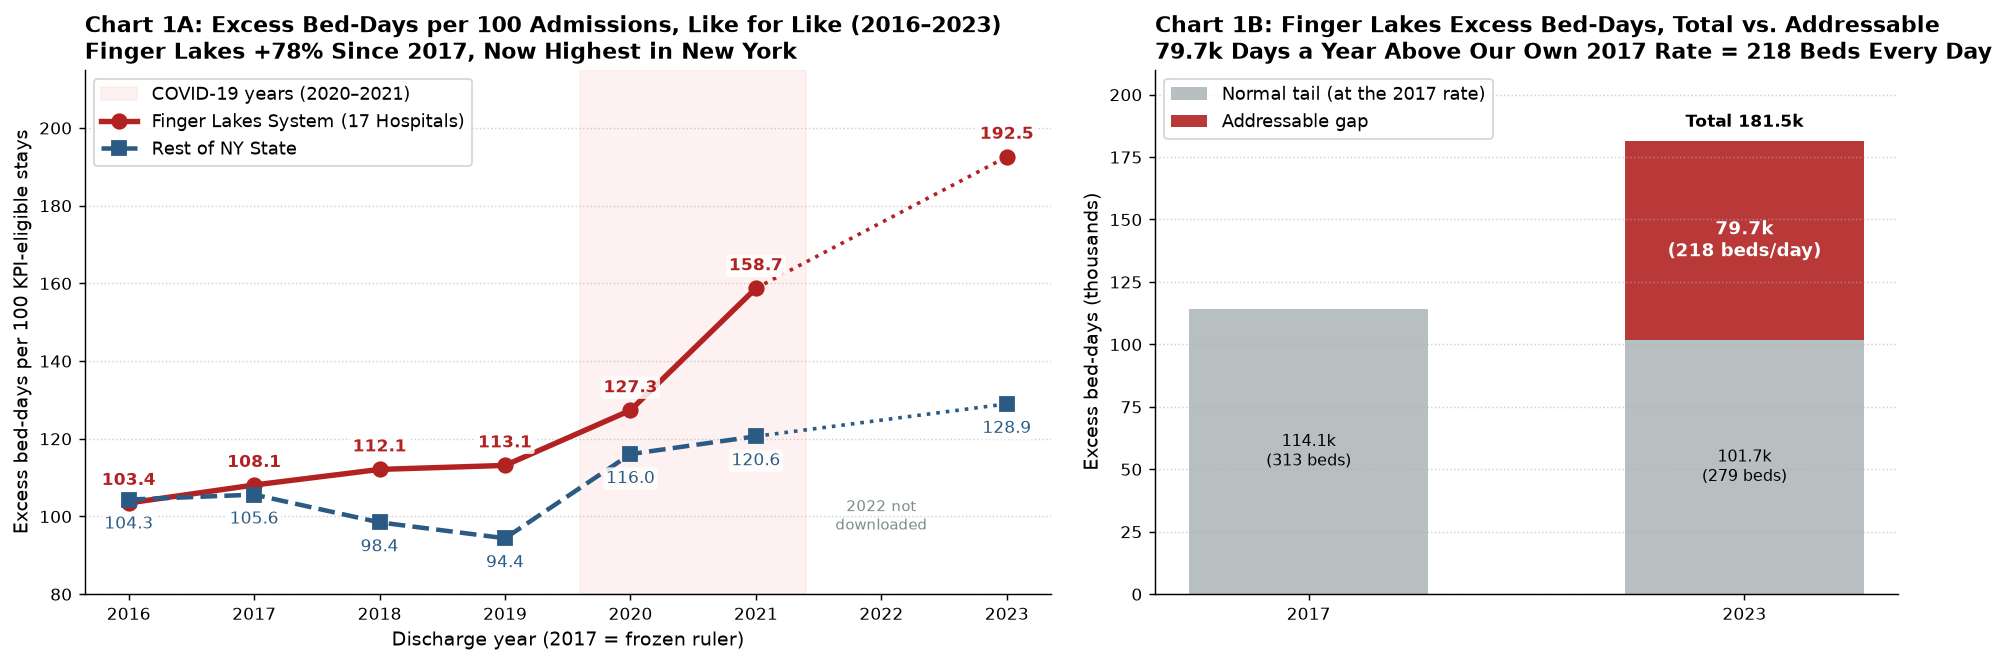

In [6]:
# ===== Chart 1: trend (like-for-like) and 2023 total vs. addressable gap =====
trend_r["group"] = np.where(trend_r["hospital_service_area"] == "Finger Lakes",
                            "Finger Lakes (17 Hospitals)", "Rest of NY State (7 Regions)")

# Like-for-like series: only codes that existed in 2017 (same ruler every year)
t_strict = trend_r.dropna(subset=["p75_strict_2017_drg"]).copy()
t_strict["excess_days"] = (t_strict["los"] - t_strict["p75_strict_2017_drg"]).clip(lower=0) * t_strict["n"]
t_strict["prolonged_stays"] = (t_strict["los"] > t_strict["p75_strict_2017_drg"]).astype(int) * t_strict["n"]
t_strict["total_days"] = t_strict["los"] * t_strict["n"]
agg_trend = t_strict.groupby(["discharge_year", "group"], as_index=False).agg(
    stays=("n", "sum"), total_days=("total_days", "sum"),
    prolonged_stays=("prolonged_stays", "sum"), excess_days=("excess_days", "sum"))
agg_trend["avg_los"] = agg_trend["total_days"] / agg_trend["stays"]
agg_trend["pct_prolonged"] = 100 * agg_trend["prolonged_stays"] / agg_trend["stays"]
agg_trend["excess_per_100"] = 100 * agg_trend["excess_days"] / agg_trend["stays"]

# All stays (headline KPI): back-up ruler for codes created after 2017
t_full = trend_r.copy()
t_full["excess_days_full"] = (t_full["los"] - t_full["p75_full"]).clip(lower=0) * t_full["n"]
agg_full_fl = (t_full[t_full["hospital_service_area"] == "Finger Lakes"]
               .groupby("discharge_year", as_index=False)
               .agg(all_kpi_stays=("n", "sum"), all_excess_days=("excess_days_full", "sum")))
agg_full_fl["all_excess_per_100"] = 100 * agg_full_fl["all_excess_days"] / agg_full_fl["all_kpi_stays"]

print("=== YEAR-BY-YEAR TREND, LIKE FOR LIKE (codes that existed in 2017) ===")
display(agg_trend.pivot(index="discharge_year", columns="group",
                        values=["avg_los", "pct_prolonged", "excess_per_100", "excess_days"]).round(1))
print("\n=== FINGER LAKES, ALL STAYS (headline KPI) ===")
display(agg_full_fl.round(1))

fl_t = agg_trend[agg_trend["group"].str.startswith("Finger Lakes")].sort_values("discharge_year")
ny_t = agg_trend[agg_trend["group"].str.startswith("Rest of NY")].sort_values("discharge_year")

# Total vs. addressable gap: the ruler's normal tail = what 2023 volume would give at our own 2017 rate
FL17 = fl_t.set_index("discharge_year").loc[2017]
RATE_2017 = float(FL17["excess_per_100"])                          # 108.1 per 100 stays
FL17_STAYS, FL17_EXCESS = int(FL17["stays"]), float(FL17["excess_days"])
FL23 = agg_full_fl.set_index("discharge_year").loc[2023]
FL23_STAYS, FL23_EXCESS = int(FL23["all_kpi_stays"]), float(FL23["all_excess_days"])
NORMAL_TAIL_23 = RATE_2017 * FL23_STAYS / 100
GAP_23 = FL23_EXCESS - NORMAL_TAIL_23
print(f"\n2023 excess bed-days {FL23_EXCESS:,.0f} = normal tail {NORMAL_TAIL_23:,.0f} "
      f"+ addressable gap {GAP_23:,.0f} ({GAP_23/365:.0f} beds/day)")

# ---- PLOT (uses only the aggregated tables above) ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.3, 1]})

ax1.axvspan(2019.6, 2021.4, color="#FADBD8", alpha=0.35, label="COVID-19 years (2020–2021)")
for df, color, marker, ls, lab, dy in [
        (fl_t, PALETTE["fl"], "o", "-", "Finger Lakes System (17 Hospitals)", 10),
        (ny_t, PALETTE["ny"], "s", "--", "Rest of NY State", -16)]:
    pre = df[df["discharge_year"] <= 2021]
    ax1.plot(pre["discharge_year"], pre["excess_per_100"], marker=marker, linestyle=ls,
             linewidth=3 if marker == "o" else 2.5, markersize=8, color=color, label=lab)
    bridge = df[df["discharge_year"].isin([2021, 2023])]
    ax1.plot(bridge["discharge_year"], bridge["excess_per_100"], linestyle=":", linewidth=2, color=color)
    last = df[df["discharge_year"] == 2023]
    ax1.plot(last["discharge_year"], last["excess_per_100"], marker=marker, markersize=8, color=color, linestyle="none")
    for _, r in df.iterrows():
        ax1.annotate(f"{r['excess_per_100']:.1f}", (r["discharge_year"], r["excess_per_100"]),
                     textcoords="offset points", xytext=(0, dy), ha="center", fontsize=9.5,
                     color=color, fontweight="bold" if marker == "o" else "normal",
                     bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
ax1.text(2022, 100, "2022 not\ndownloaded", ha="center", va="center", fontsize=8.5, color=PALETTE["grey"])
growth = 100 * (fl_t["excess_per_100"].iloc[-1] / RATE_2017 - 1)
ax1.set_title(f"Chart 1A: Excess Bed-Days per 100 Admissions, Like for Like (2016–2023)\n"
              f"Finger Lakes +{growth:.0f}% Since 2017, Now Highest in New York", loc="left", fontsize=12)
ax1.set_xlabel("Discharge year (2017 = frozen ruler)")
ax1.set_ylabel("Excess bed-days per 100 KPI-eligible stays")
ax1.set_xticks([2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])
ax1.set_ylim(80, 215)
ax1.grid(axis="y", linestyle=":", alpha=0.6)
ax1.legend(loc="upper left", frameon=True)

labels = ["2017", "2023"]
tail = [FL17_EXCESS / 1000, NORMAL_TAIL_23 / 1000]
gap = [0, GAP_23 / 1000]
ax2.bar(labels, tail, width=0.55, color=PALETTE["grey"], alpha=0.55, label="Normal tail (at the 2017 rate)")
ax2.bar(labels, gap, width=0.55, bottom=tail, color=PALETTE["fl"], alpha=0.9, label="Addressable gap")
ax2.text(0, tail[0] / 2, f"{tail[0]:.1f}k\n({FL17_EXCESS/365:.0f} beds)", ha="center", va="center", fontsize=9)
ax2.text(1, tail[1] / 2, f"{tail[1]:.1f}k\n({NORMAL_TAIL_23/365:.0f} beds)", ha="center", va="center", fontsize=9)
ax2.text(1, tail[1] + gap[1] / 2, f"{gap[1]:.1f}k\n({GAP_23/365:.0f} beds/day)", ha="center", va="center",
         fontsize=10, fontweight="bold", color="white")
ax2.text(1, tail[1] + gap[1] + 4, f"Total {FL23_EXCESS/1000:.1f}k", ha="center", va="bottom", fontsize=9.5, fontweight="bold")
ax2.set_title(f"Chart 1B: Finger Lakes Excess Bed-Days, Total vs. Addressable\n"
              f"{GAP_23/1000:.1f}k Days a Year Above Our Own 2017 Rate = {GAP_23/365:.0f} Beds Every Day",
              loc="left", fontsize=12)
ax2.set_ylabel("Excess bed-days (thousands)")
ax2.set_ylim(0, 210)
ax2.grid(axis="y", linestyle=":", alpha=0.6)
ax2.legend(loc="upper left", frameon=True)

plt.tight_layout(pad=1.8)
plt.savefig(FIG_DIR / "chart1_trend_cost_of_doing_nothing.png", bbox_inches="tight")
plt.show()

---
## Step 3: Where do the excess days go? (Task 4, Chart 2)

We group stays by **`patient_disposition`**, where the patient goes at discharge. It is known only at discharge, so we use it to **explain** the problem, never as a model input.
1. **Home without help:** **56.6% of patients**, average stay **4.2 days**, **23.0% of excess bed-days** (78 per 100 stays).
2. **Nursing home (SNF):** only **14.7% of patients**, but average stay **12.5 days**. **Half of them (49.3%)** overstay: **515 excess days per 100 stays (6.6× home)** and **39.4% of all excess bed-days**.
3. **Home health care, rehab and hospice:** another **35.4%** of excess bed-days.

### Why this matters to the board
Patients who need post-hospital care are **41% of stays but 74.8% of excess bed-days (135,668 days)**. The data shows **where** the days are, not **why**: it can't tell us when a patient was medically ready to leave. But the pattern is consistent with placement being arranged too late, which is exactly what Day-1 discharge planning addresses.

Post-hospital care: 40.6% of stays, 74.8% of excess days (135,668 days); SNF vs. home: 6.6x
=== WHERE PATIENTS GO AT DISCHARGE (FINGER LAKES 2023, n = 94,132) ===


,disp_group,stays,share_stays_pct,avg_los,prolonged_pct,excess_per_100,excess_days,share_excess_pct,cost_per_day
0,1. Routine Home (Self Care),53303,56.6,4.2,14.6,78.2,41662,23.0,3264.9
1,2. Skilled Nursing Facility (SNF),13871,14.7,12.5,49.3,514.8,71407,39.4,2182.3
2,3. Home w/ Home Health Care,20642,21.9,8.1,30.5,218.6,45128,24.9,2927.9
3,4. Rehab / Custodial / LTC Facility,1729,1.8,13.6,44.2,477.8,8262,4.6,3170.7
4,5. Hospice (Home or Medical Facility),1949,2.1,13.7,44.0,557.8,10871,6.0,2072.0
5,6. AMA / Psych / Court / Other,2638,2.8,4.9,16.1,156.6,4130,2.3,2527.7


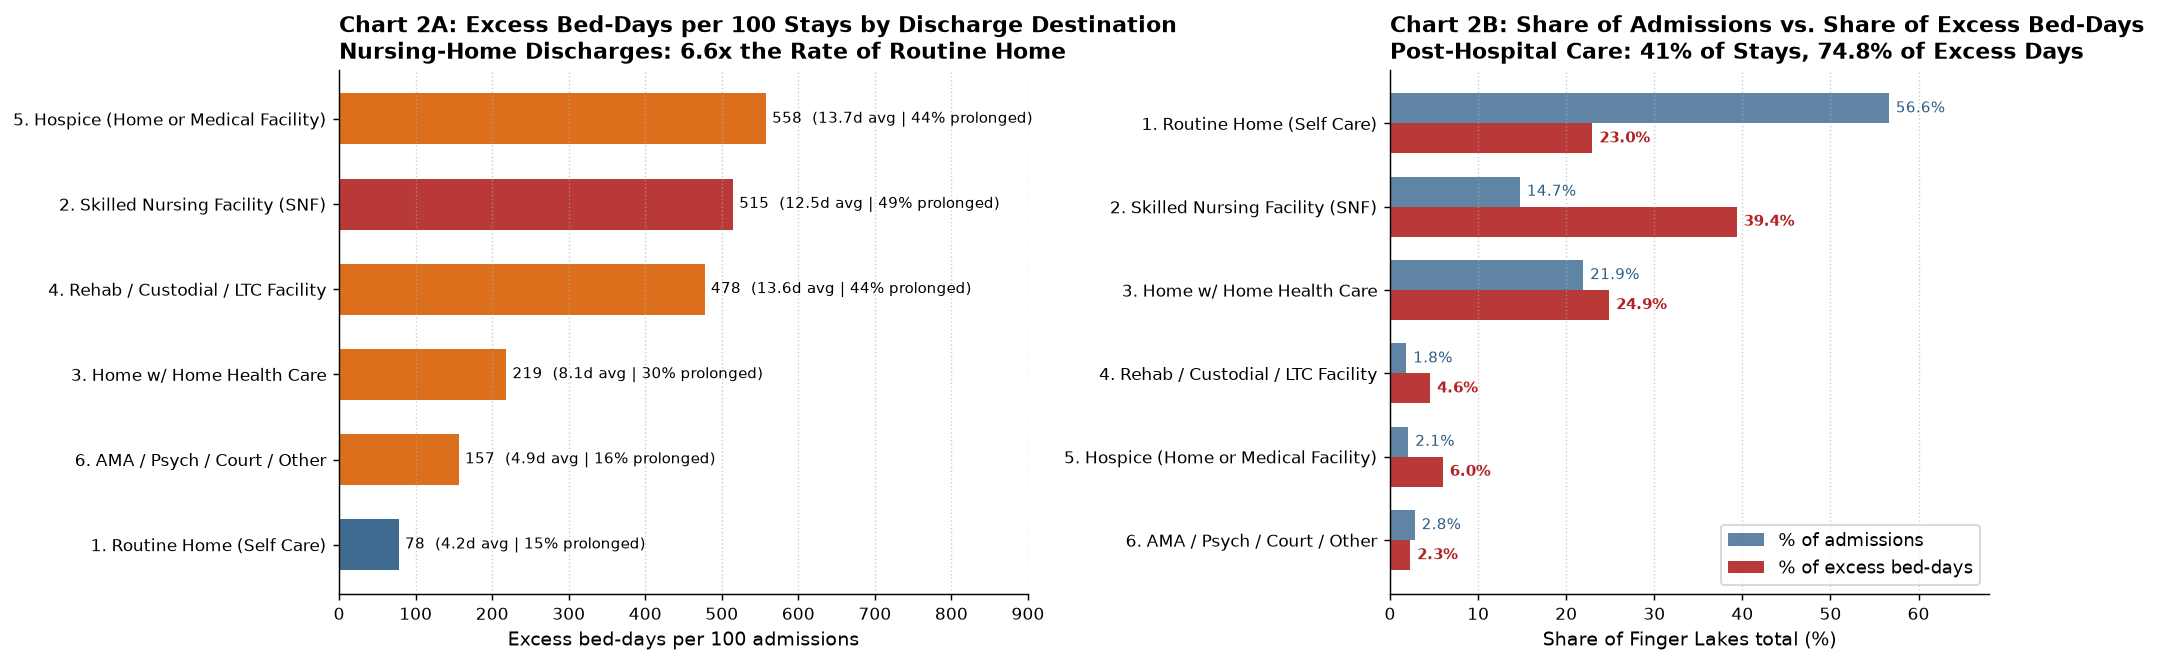

In [7]:
# ===== Chart 2: where the excess days go (discharge destination) =====
fl23 = stays23_r[stays23_r["business_case_system"] & stays23_r["kpi_eligible"]].copy()
fl23["excess_days"] = (fl23["los"] - fl23["p75_full"]).clip(lower=0)
fl23["prolonged"] = fl23["los"] > fl23["p75_full"]

def map_disp_group(d):
    if d == "Home or Self Care":
        return "1. Routine Home (Self Care)"
    elif d == "Skilled Nursing Home":
        return "2. Skilled Nursing Facility (SNF)"
    elif d == "Home w/ Home Health Services":
        return "3. Home w/ Home Health Care"
    elif d in ("Inpatient Rehabilitation Facility", "Hosp Basd Medicare Approved Swing Bed",
               "Medicare Cert Long Term Care Hospital", "Facility w/ Custodial/Supportive Care"):
        return "4. Rehab / Custodial / LTC Facility"
    elif "Hospice" in str(d):
        return "5. Hospice (Home or Medical Facility)"
    else:
        return "6. AMA / Psych / Court / Other"

fl23["disp_group"] = fl23["patient_disposition"].astype(str).map(map_disp_group)
disp_summary = fl23.groupby("disp_group", as_index=False).agg(
    stays=("los", "count"), avg_los=("los", "mean"), prolonged_stays=("prolonged", "sum"),
    excess_days=("excess_days", "sum"), total_costs=("total_costs", "sum"), total_days=("los", "sum"))
disp_summary["share_stays_pct"] = 100 * disp_summary["stays"] / disp_summary["stays"].sum()
disp_summary["prolonged_pct"] = 100 * disp_summary["prolonged_stays"] / disp_summary["stays"]
disp_summary["excess_per_100"] = 100 * disp_summary["excess_days"] / disp_summary["stays"]
disp_summary["share_excess_pct"] = 100 * disp_summary["excess_days"] / disp_summary["excess_days"].sum()
disp_summary["cost_per_day"] = disp_summary["total_costs"] / disp_summary["total_days"]

post_acute = disp_summary["disp_group"].str[:1].isin(["2", "3", "4", "5"])
POST_ACUTE_SHARE_STAYS = disp_summary.loc[post_acute, "share_stays_pct"].sum()
POST_ACUTE_SHARE_EXCESS = disp_summary.loc[post_acute, "share_excess_pct"].sum()
POST_ACUTE_EXCESS_DAYS = disp_summary.loc[post_acute, "excess_days"].sum()
SNF_RATIO = (disp_summary.set_index("disp_group").loc["2. Skilled Nursing Facility (SNF)", "excess_per_100"]
             / disp_summary.set_index("disp_group").loc["1. Routine Home (Self Care)", "excess_per_100"])
print(f"Post-hospital care: {POST_ACUTE_SHARE_STAYS:.1f}% of stays, {POST_ACUTE_SHARE_EXCESS:.1f}% of excess days "
      f"({POST_ACUTE_EXCESS_DAYS:,.0f} days); SNF vs. home: {SNF_RATIO:.1f}x")

print(f"=== WHERE PATIENTS GO AT DISCHARGE (FINGER LAKES 2023, n = {len(fl23):,}) ===")
display(disp_summary[["disp_group", "stays", "share_stays_pct", "avg_los", "prolonged_pct",
                      "excess_per_100", "excess_days", "share_excess_pct", "cost_per_day"]].round(1))

# ---- PLOT (uses only the aggregated tables above) ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})

d_plot = disp_summary.sort_values("excess_per_100", ascending=True)
colors_d = [PALETTE["ny"] if "Routine Home" in g else (PALETTE["fl"] if "SNF" in g else PALETTE["amber"])
            for g in d_plot["disp_group"]]
bars1 = ax1.barh(d_plot["disp_group"], d_plot["excess_per_100"], color=colors_d, alpha=0.9, height=0.6)
for bar, (_, r) in zip(bars1, d_plot.iterrows()):
    ax1.text(bar.get_width() + 8, bar.get_y() + bar.get_height() / 2,
             f"{r['excess_per_100']:.0f}  ({r['avg_los']:.1f}d avg | {r['prolonged_pct']:.0f}% prolonged)",
             va="center", fontsize=8.5)
ax1.set_title(f"Chart 2A: Excess Bed-Days per 100 Stays by Discharge Destination\n"
              f"Nursing-Home Discharges: {SNF_RATIO:.1f}x the Rate of Routine Home", loc="left")
ax1.set_xlabel("Excess bed-days per 100 admissions")
ax1.set_xlim(0, 900)
ax1.grid(axis="x", linestyle=":", alpha=0.6)

d_plot2 = disp_summary.sort_values("disp_group", ascending=False)
y_pos = np.arange(len(d_plot2))
h = 0.36
b_stays = ax2.barh(y_pos + h / 2, d_plot2["share_stays_pct"], height=h, color=PALETTE["ny"], alpha=0.75, label="% of admissions")
b_exc = ax2.barh(y_pos - h / 2, d_plot2["share_excess_pct"], height=h, color=PALETTE["fl"], alpha=0.9, label="% of excess bed-days")
for bar in b_stays:
    ax2.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2, f"{bar.get_width():.1f}%", va="center", fontsize=8.5, color=PALETTE["ny"])
for bar in b_exc:
    ax2.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2, f"{bar.get_width():.1f}%", va="center", fontsize=8.5, fontweight="bold", color=PALETTE["fl"])
ax2.set_yticks(y_pos)
ax2.set_yticklabels(d_plot2["disp_group"])
ax2.set_title(f"Chart 2B: Share of Admissions vs. Share of Excess Bed-Days\n"
              f"Post-Hospital Care: {POST_ACUTE_SHARE_STAYS:.0f}% of Stays, {POST_ACUTE_SHARE_EXCESS:.1f}% of Excess Days", loc="left")
ax2.set_xlabel("Share of Finger Lakes total (%)")
ax2.set_xlim(0, 68)
ax2.grid(axis="x", linestyle=":", alpha=0.6)
ax2.legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.savefig(FIG_DIR / "chart2_discharge_disposition_bottleneck.png", bbox_inches="tight")
plt.show()

---
## Step 4: Regions and hospitals: where to act first (Task 4, Chart 3)

Because the KPI compares like-for-like patients (same diagnosis and severity), we can compare regions and hospitals:
1. **Across New York State (Chart 3A):** Finger Lakes (**192.8** per 100 stays) is the highest of the 8 regions, against 129.9 for the rest of the state and 100.8 for Long Island. The ruler adjusts for diagnosis and severity, but not for everything: an academic referral centre such as Strong Memorial receives harder cases within the same group. Process differences are the likely main driver, which WP3 will test with more patient-mix controls (hypothesis H3).
2. **Inside Finger Lakes (Chart 3B):** the **4 large Rochester hospitals** (Strong Memorial 270.3, Unity 211.0, Rochester General 204.2, Highland 188.5) hold **76% of stays but 89% of excess bed-days (162,018 days)**.
3. **Takeaway:** start the programme in those 4 hospitals. They carry almost 9 in 10 excess days, and they are also where the rate per stay is highest.

=== ALL 8 NEW YORK REGIONS (2023, all stays = headline KPI) ===


,hospital_service_area,stays,avg_los,prolonged_pct,excess_per_100_full,excess_per_100_strict,excess_days,cost_per_day
2,Finger Lakes,94132,6.7,24.4,192.8,192.5,181460,2808.0
5,New York City,614197,6.0,22.8,150.6,149.9,925012,5901.7
6,Southern Tier,17946,6.3,21.9,136.8,137.4,24552,2937.7
7,Western NY,88969,5.8,21.7,129.8,126.2,115478,3122.2
3,Hudson Valley,147048,5.9,21.8,114.6,114.1,168570,4453.4
0,Capital/Adirond,91531,5.9,19.6,112.1,111.4,102580,2959.3
1,Central NY,85317,5.6,20.7,110.5,108.3,94254,3460.8
4,Long Island,251086,5.4,19.3,100.8,100.0,253114,4756.3


Rest of NY State (stay-weighted): 129.9 excess days per 100 stays
Top 4 hospitals: 76.2% of stays, 89.3% of excess days (162,018 days)

=== ALL 17 HOSPITALS IN FINGER LAKES (2023) ===


,facility_name,stays,avg_los,prolonged_pct,snf_pct,excess_per_100,excess_days,share_stays_pct,share_excess_pct,cum_share_excess_pct,cost_per_day
6,Strong Memorial Hospital,24536,8.3,25.4,10.7,270.3,66326,26.1,36.6,36.6,3729.4
4,Rochester General Hospital,21936,6.8,25.6,13.6,204.2,44784,23.3,24.7,61.2,2809.8
7,The Unity Hospital of Rochester,14464,6.8,29.9,17.5,211.0,30515,15.4,16.8,78.0,2355.0
3,Highland Hospital,10818,6.4,25.1,17.4,188.5,20393,11.5,11.2,89.3,1678.0
0,Arnot Ogden Medical Center,5034,4.7,18.9,17.1,88.7,4464,5.3,2.5,91.7,2931.9
10,F.F. Thompson Hospital,3830,5.2,18.2,17.5,93.4,3579,4.1,2.0,93.7,1755.0
15,Newark-Wayne Community Hospital,3629,4.9,20.0,15.3,93.7,3401,3.9,1.9,95.6,2023.6
8,Geneva General Hospital,2253,4.9,18.7,15.2,93.5,2106,2.4,1.2,96.8,2536.6
9,Clifton Springs Hospital and Clinic,1482,5.2,21.3,17.5,123.5,1830,1.6,1.0,97.8,1540.3
12,Corning Hospital,3140,4.5,14.4,16.7,50.4,1583,3.3,0.9,98.6,2922.6


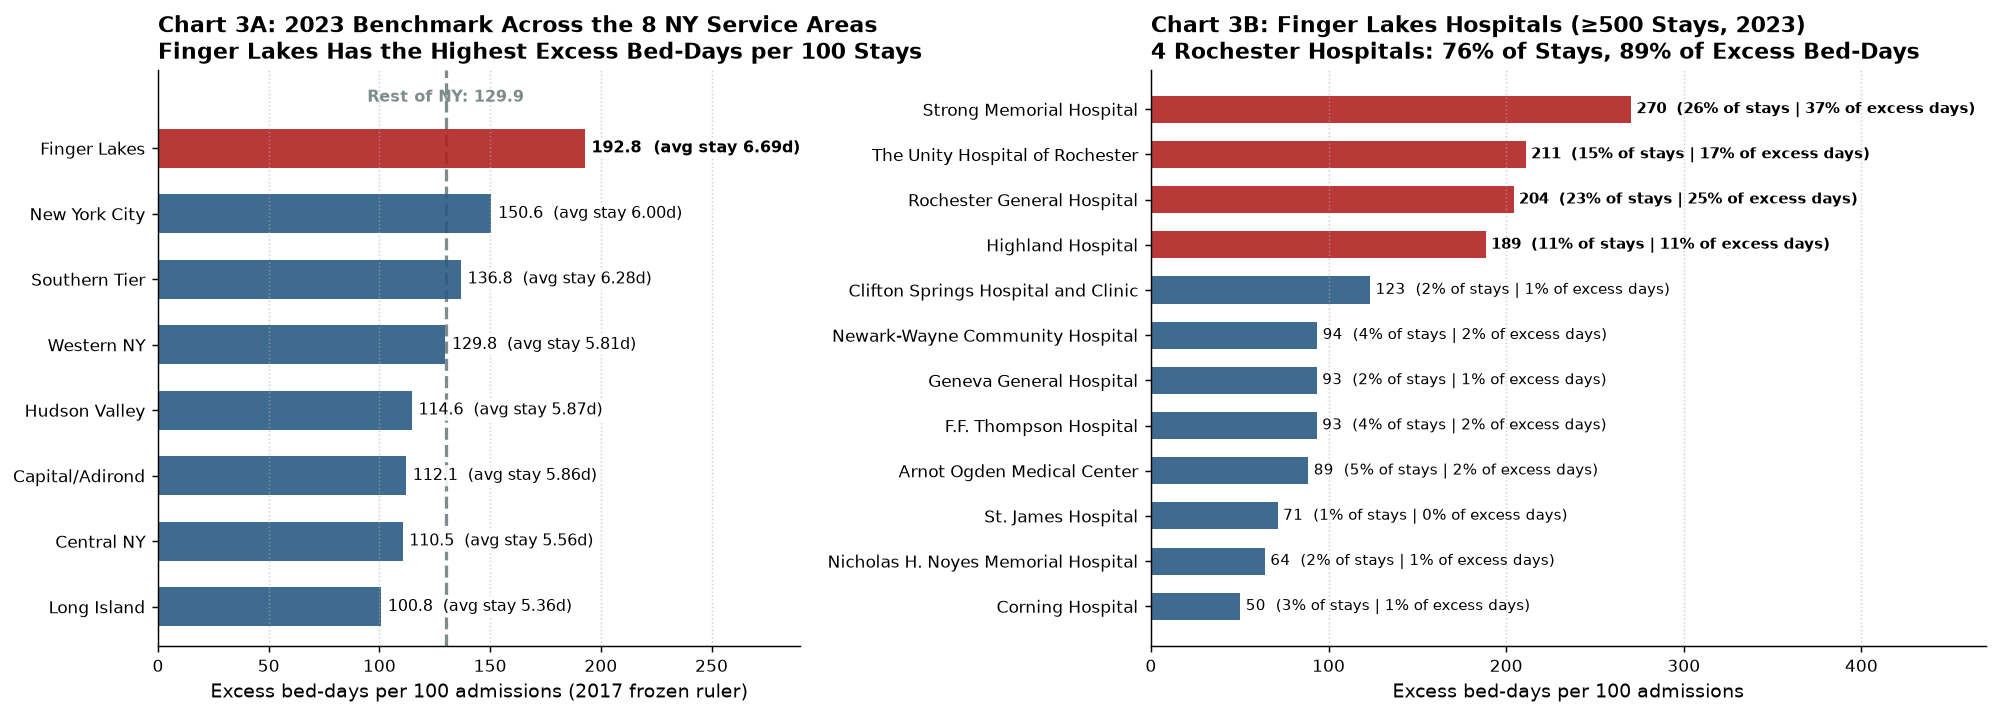

In [8]:
# ===== Chart 3: regions and hospitals =====
s23_kpi = stays23_r[stays23_r["kpi_eligible"]].copy()
s23_kpi["excess_full"] = (s23_kpi["los"] - s23_kpi["p75_full"]).clip(lower=0)
s23_kpi["prolonged_full"] = s23_kpi["los"] > s23_kpi["p75_full"]
s23_kpi["excess_strict"] = (s23_kpi["los"] - s23_kpi["p75_strict_2017_drg"]).clip(lower=0)

reg_bench = s23_kpi.groupby("hospital_service_area", observed=True, as_index=False).agg(
    stays=("los", "count"), avg_los=("los", "mean"), prolonged_stays=("prolonged_full", "sum"),
    excess_days=("excess_full", "sum"), total_costs=("total_costs", "sum"), total_days=("los", "sum"))
reg_strict = (s23_kpi.dropna(subset=["p75_strict_2017_drg"])
              .groupby("hospital_service_area", observed=True, as_index=False)
              .agg(stays_strict=("los", "count"), excess_strict=("excess_strict", "sum")))
reg_strict["excess_per_100_strict"] = 100 * reg_strict["excess_strict"] / reg_strict["stays_strict"]
reg_bench = reg_bench.merge(reg_strict[["hospital_service_area", "excess_per_100_strict"]], on="hospital_service_area")
reg_bench["prolonged_pct"] = 100 * reg_bench["prolonged_stays"] / reg_bench["stays"]
reg_bench["excess_per_100_full"] = 100 * reg_bench["excess_days"] / reg_bench["stays"]
reg_bench["cost_per_day"] = reg_bench["total_costs"] / reg_bench["total_days"]
reg_bench = reg_bench.sort_values("excess_per_100_full", ascending=False)
rest = reg_bench[reg_bench["hospital_service_area"] != "Finger Lakes"]
REST_NY_MEAN = 100 * rest["excess_days"].sum() / rest["stays"].sum()   # stay-weighted, all stays

print("=== ALL 8 NEW YORK REGIONS (2023, all stays = headline KPI) ===")
display(reg_bench[["hospital_service_area", "stays", "avg_los", "prolonged_pct",
                   "excess_per_100_full", "excess_per_100_strict", "excess_days", "cost_per_day"]].round(1))
print(f"Rest of NY State (stay-weighted): {REST_NY_MEAN:.1f} excess days per 100 stays")

fl23_fac = fl23.merge(fac23[["permanent_facility_id", "facility_name"]], on="permanent_facility_id", how="left")
hosp_bench = fl23_fac.groupby(["permanent_facility_id", "facility_name"], as_index=False).agg(
    stays=("los", "count"), avg_los=("los", "mean"), prolonged_stays=("prolonged", "sum"),
    excess_days=("excess_days", "sum"), total_costs=("total_costs", "sum"), total_days=("los", "sum"),
    snf_stays=("patient_disposition", lambda s: (s == "Skilled Nursing Home").sum()))
hosp_bench["prolonged_pct"] = 100 * hosp_bench["prolonged_stays"] / hosp_bench["stays"]
hosp_bench["excess_per_100"] = 100 * hosp_bench["excess_days"] / hosp_bench["stays"]
hosp_bench["share_stays_pct"] = 100 * hosp_bench["stays"] / hosp_bench["stays"].sum()
hosp_bench["share_excess_pct"] = 100 * hosp_bench["excess_days"] / hosp_bench["excess_days"].sum()
hosp_bench = hosp_bench.sort_values("excess_days", ascending=False)
hosp_bench["cum_share_excess_pct"] = hosp_bench["share_excess_pct"].cumsum()
hosp_bench["snf_pct"] = 100 * hosp_bench["snf_stays"] / hosp_bench["stays"]
hosp_bench["cost_per_day"] = hosp_bench["total_costs"] / hosp_bench["total_days"]
top4 = hosp_bench.head(4)
TOP4_STAY_SHARE, TOP4_EXCESS_SHARE = top4["share_stays_pct"].sum(), top4["share_excess_pct"].sum()
print(f"Top 4 hospitals: {TOP4_STAY_SHARE:.1f}% of stays, {TOP4_EXCESS_SHARE:.1f}% of excess days "
      f"({top4['excess_days'].sum():,.0f} days)")

print("\n=== ALL 17 HOSPITALS IN FINGER LAKES (2023) ===")
display(hosp_bench[["facility_name", "stays", "avg_los", "prolonged_pct", "snf_pct", "excess_per_100",
                    "excess_days", "share_stays_pct", "share_excess_pct", "cum_share_excess_pct", "cost_per_day"]].round(1))

# ---- PLOT (uses only the aggregated tables above) ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 5.6), gridspec_kw={"width_ratios": [1, 1.3]})

r_plot = reg_bench.sort_values("excess_per_100_full", ascending=True)
r_colors = [PALETTE["fl"] if h == "Finger Lakes" else PALETTE["ny"] for h in r_plot["hospital_service_area"]]
b1 = ax1.barh(r_plot["hospital_service_area"].astype(str), r_plot["excess_per_100_full"], color=r_colors, alpha=0.9, height=0.6)
ax1.axvline(REST_NY_MEAN, color=PALETTE["grey"], linestyle="--", linewidth=1.8, zorder=0)
ax1.text(REST_NY_MEAN, len(r_plot) - 0.35, f"Rest of NY: {REST_NY_MEAN:.1f}", ha="center", va="bottom",
         fontsize=9, color=PALETTE["grey"], fontweight="bold")
for bar, (_, r) in zip(b1, r_plot.iterrows()):
    ax1.text(bar.get_width() + 3, bar.get_y() + bar.get_height() / 2,
             f"{r['excess_per_100_full']:.1f}  (avg stay {r['avg_los']:.2f}d)", va="center", fontsize=9,
             fontweight="bold" if r["hospital_service_area"] == "Finger Lakes" else "normal",
             bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))
ax1.set_title("Chart 3A: 2023 Benchmark Across the 8 NY Service Areas\nFinger Lakes Has the Highest Excess Bed-Days per 100 Stays", loc="left")
ax1.set_xlabel("Excess bed-days per 100 admissions (2017 frozen ruler)")
ax1.set_xlim(0, 290)
ax1.set_ylim(-0.6, len(r_plot) + 0.2)
ax1.grid(axis="x", linestyle=":", alpha=0.6)

h_top = hosp_bench[hosp_bench["stays"] >= 500].sort_values("excess_per_100", ascending=True)
top4_names = set(top4["facility_name"])
h_colors = [PALETTE["fl"] if n in top4_names else PALETTE["ny"] for n in h_top["facility_name"]]
b2 = ax2.barh(h_top["facility_name"].astype(str), h_top["excess_per_100"], color=h_colors, alpha=0.9, height=0.6)
for bar, (_, r) in zip(b2, h_top.iterrows()):
    ax2.text(bar.get_width() + 3, bar.get_y() + bar.get_height() / 2,
             f"{r['excess_per_100']:.0f}  ({r['share_stays_pct']:.0f}% of stays | {r['share_excess_pct']:.0f}% of excess days)",
             va="center", fontsize=8.5, fontweight="bold" if r["facility_name"] in top4_names else "normal")
ax2.set_title(f"Chart 3B: Finger Lakes Hospitals (≥500 Stays, 2023)\n"
              f"4 Rochester Hospitals: {TOP4_STAY_SHARE:.0f}% of Stays, {TOP4_EXCESS_SHARE:.0f}% of Excess Bed-Days", loc="left")
ax2.set_xlabel("Excess bed-days per 100 admissions")
ax2.set_xlim(0, 470)
ax2.grid(axis="x", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(FIG_DIR / "chart3_regional_and_hospital_benchmarks.png", bbox_inches="tight")
plt.show()

---
## Step 5: Which conditions cause the most excess days? (Task 4, Chart 4)

Finger Lakes had **272** active medical-surgical diagnosis groups (APR-DRGs) in 2023. Case managers don't need to watch them all equally:
* **15 conditions account for 37.3%** of excess bed-days.
* **The top 30 (11% of groups) account for 52.6%.**
* The top conditions are **septicaemia (15,738 excess days)**, **heart failure (7,625)**, **infections with surgery (5,863)**, **major lung infections (5,207)**, **degenerative brain disorders including dementia (5,063)** and **stroke (3,846)**.
* In most of them, **40–63% of patients leave for a nursing home or home health care**.

Total active APR-DRGs in Finger Lakes 2023: 272
  Top 10 conditions ->  30.7% of all excess bed-days (55,709 days)
  Top 15 conditions ->  37.3% of all excess bed-days (67,649 days)
  Top 20 conditions ->  43.2% of all excess bed-days (78,377 days)
  Top 30 conditions ->  52.6% of all excess bed-days (95,509 days)
  Top 50 conditions ->  65.6% of all excess bed-days (119,094 days)

=== TOP 15 MEDICAL CONDITIONS DRIVING EXCESS BED-DAYS (2023) ===


,rank,apr_drg_code,apr_drg_description,stays,avg_los,prolonged_pct,snf_hh_pct,excess_per_100,excess_days,share_excess_pct,cum_share_excess_pct
0,1,720,SEPTICEMIA AND DISSEMINATED INFECTIONS,"7,778",8.2 d,23.3%,42.1%,202.3,"15,738",8.7%,8.7%
1,2,194,HEART FAILURE,"4,257",6.6 d,26.8%,41.7%,179.1,"7,625",4.2%,12.9%
2,3,710,INFECTIOUS AND PARASITIC DISEASES INCLUDING HIV WITH O.R. PROCEDURE,868,20.2 d,34.1%,62.9%,675.5,"5,863",3.2%,16.1%
3,4,137,MAJOR RESPIRATORY INFECTIONS AND INFLAMMATIONS,"2,815",7.3 d,19.3%,44.4%,185.0,"5,207",2.9%,19.0%
4,5,042,DEGENERATIVE NERVOUS SYSTEM DISORDERS EXCEPT MULTIPLE SCLEROSIS,618,15.2 d,39.2%,60.8%,819.3,"5,063",2.8%,21.8%
5,6,045,CVA AND PRECEREBRAL OCCLUSION WITH INFARCTION,"1,893",6.2 d,24.8%,42.8%,203.2,"3,846",2.1%,23.9%
6,7,052,ALTERATION IN CONSCIOUSNESS,"1,122",8.3 d,25.2%,55.7%,325.4,"3,651",2.0%,25.9%
7,8,469,ACUTE KIDNEY INJURY,"1,830",6.4 d,27.7%,39.0%,179.8,"3,291",1.8%,27.7%
8,9,133,RESPIRATORY FAILURE,"1,384",6.6 d,25.7%,40.2%,207.8,"2,876",1.6%,29.3%
9,10,662,SICKLE CELL ANEMIA CRISIS,332,12.8 d,45.2%,3.9%,767.8,"2,549",1.4%,30.7%


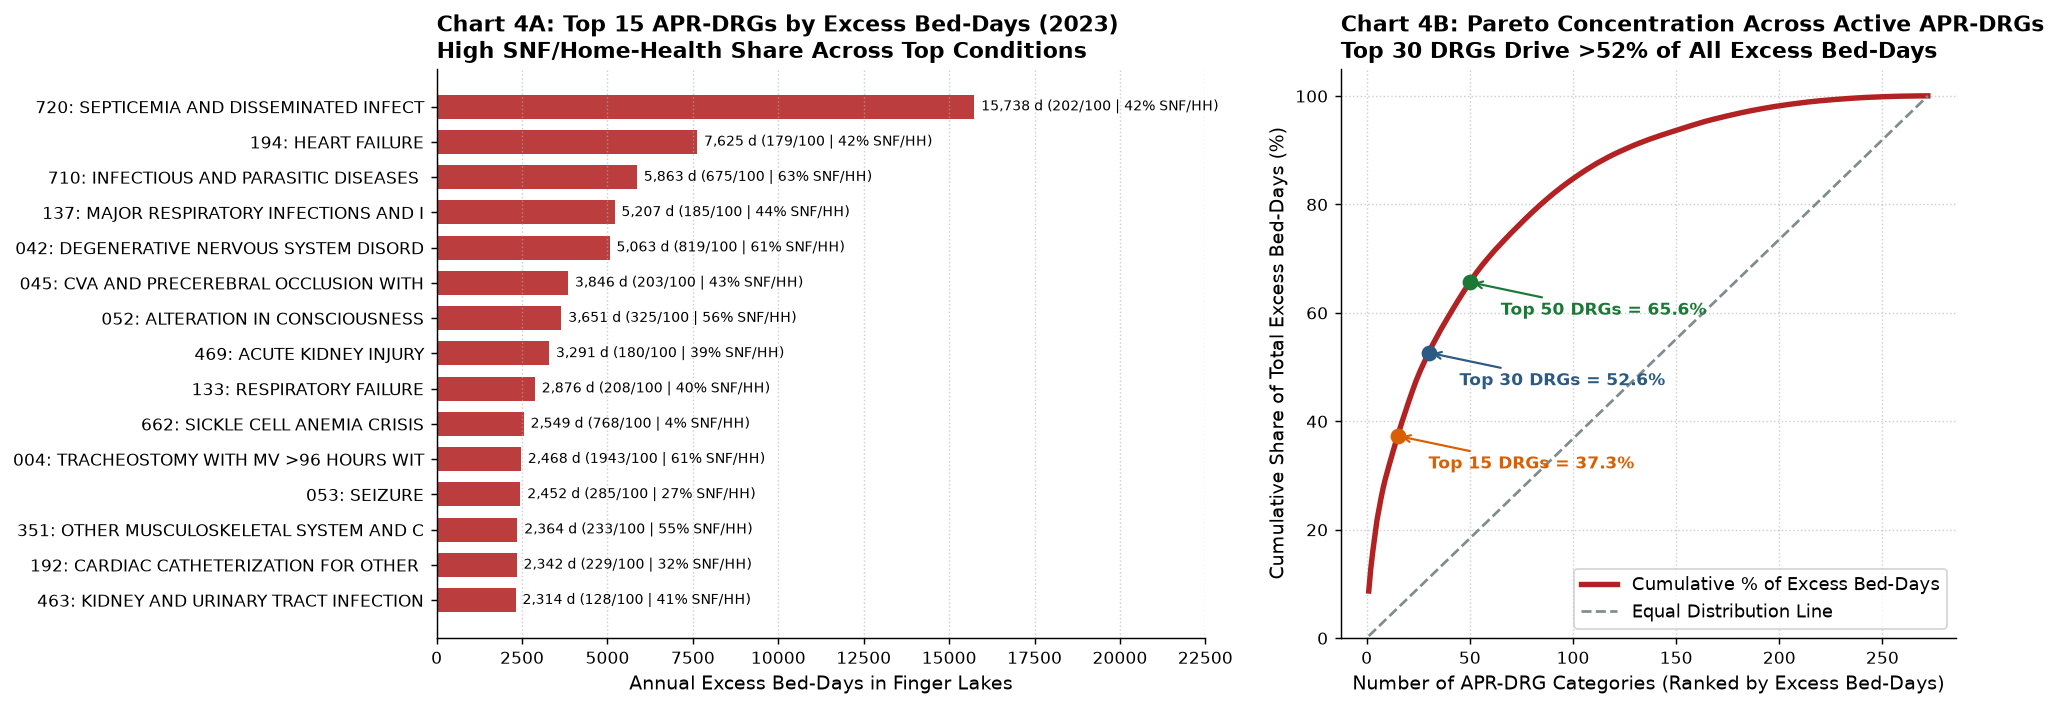

In [9]:
drg_pareto = fl23.groupby("apr_drg_code", as_index=False).agg(
    stays=("los", "count"),
    avg_los=("los", "mean"),
    prolonged_stays=("prolonged", "sum"),
    excess_days=("excess_days", "sum"),
    total_costs=("total_costs", "sum"),
    snf_homehealth_stays=("patient_disposition", lambda s: s.isin(["Skilled Nursing Home", "Home w/ Home Health Services"]).sum()),
).merge(drg_lk[["apr_drg_code", "apr_drg_description"]], on="apr_drg_code", how="left")

drg_pareto = drg_pareto.sort_values("excess_days", ascending=False).reset_index(drop=True)
drg_pareto["rank"] = np.arange(1, len(drg_pareto) + 1)
drg_pareto["prolonged_pct"] = 100 * drg_pareto["prolonged_stays"] / drg_pareto["stays"]
drg_pareto["snf_hh_pct"] = 100 * drg_pareto["snf_homehealth_stays"] / drg_pareto["stays"]
drg_pareto["excess_per_100"] = 100 * drg_pareto["excess_days"] / drg_pareto["stays"]
drg_pareto["share_excess_pct"] = 100 * drg_pareto["excess_days"] / drg_pareto["excess_days"].sum()
drg_pareto["cum_share_excess_pct"] = drg_pareto["share_excess_pct"].cumsum()

print(f"Total active APR-DRGs in Finger Lakes 2023: {len(drg_pareto)}")
for k in (10, 15, 20, 30, 50):
    row_k = drg_pareto.iloc[k - 1]
    print(f"  Top {k:>2} conditions -> {row_k['cum_share_excess_pct']:5.1f}% of all excess bed-days ({drg_pareto.iloc[:k]['excess_days'].sum():,.0f} days)")

print("\n=== TOP 15 MEDICAL CONDITIONS DRIVING EXCESS BED-DAYS (2023) ===")
display(drg_pareto.head(15)[[
    "rank", "apr_drg_code", "apr_drg_description", "stays", "avg_los",
    "prolonged_pct", "snf_hh_pct", "excess_per_100", "excess_days", "share_excess_pct", "cum_share_excess_pct"
]].style.format({
    "stays": "{:,.0f}",
    "avg_los": "{:.1f} d",
    "prolonged_pct": "{:.1f}%",
    "snf_hh_pct": "{:.1f}%",
    "excess_per_100": "{:.1f}",
    "excess_days": "{:,.0f}",
    "share_excess_pct": "{:.1f}%",
    "cum_share_excess_pct": "{:.1f}%",
}))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 5.8), gridspec_kw={"width_ratios": [1.25, 1]})

top15 = drg_pareto.head(15).iloc[::-1].copy()
top15["short_label"] = top15["apr_drg_code"] + ": " + top15["apr_drg_description"].fillna("Unknown DRG").str.slice(0, 34)
b4 = ax1.barh(top15["short_label"], top15["excess_days"], color=PALETTE["fl"], alpha=0.88, height=0.68)
for bar, (_, r) in zip(b4, top15.iterrows()):
    ax1.text(bar.get_width() + 200, bar.get_y() + bar.get_height()/2,
             f"{r['excess_days']:,.0f} d ({r['excess_per_100']:.0f}/100 | {r['snf_hh_pct']:.0f}% SNF/HH)",
             va="center", fontsize=8)

ax1.set_title("Chart 4A: Top 15 APR-DRGs by Excess Bed-Days (2023)\nHigh SNF/Home-Health Share Across Top Conditions", loc="left", fontsize=12)
ax1.set_xlabel("Annual Excess Bed-Days in Finger Lakes")
ax1.set_xlim(0, 22500)
ax1.grid(axis="x", linestyle=":", alpha=0.6)

ax2.plot(drg_pareto["rank"], drg_pareto["cum_share_excess_pct"], color=PALETTE["fl"], linewidth=3, label="Cumulative % of Excess Bed-Days")
ax2.plot([1, len(drg_pareto)], [100/len(drg_pareto), 100], linestyle="--", color=PALETTE["grey"], label="Equal Distribution Line")

for k, col in [(15, PALETTE["amber"]), (30, PALETTE["ny"]), (50, PALETTE["teal"])]:
    val = drg_pareto.loc[drg_pareto["rank"] == k, "cum_share_excess_pct"].iloc[0]
    ax2.scatter([k], [val], color=col, s=60, zorder=5)
    ax2.annotate(f"Top {k} DRGs = {val:.1f}%", (k, val), xytext=(k + 15, val - 6),
                 arrowprops=dict(arrowstyle="->", color=col, lw=1.2), fontweight="bold", color=col, fontsize=9.5)

ax2.set_title("Chart 4B: Pareto Concentration Across Active APR-DRGs\nTop 30 DRGs Drive >52% of All Excess Bed-Days", loc="left", fontsize=12)
ax2.set_xlabel("Number of APR-DRG Categories (Ranked by Excess Bed-Days)")
ax2.set_ylabel("Cumulative Share of Total Excess Bed-Days (%)")
ax2.set_ylim(0, 105)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower right")

plt.tight_layout(pad=2.0)
plt.savefig(FIG_DIR / "chart4_drg_pareto_concentration.png", bbox_inches="tight")
plt.show()

---
## Step 6: Can we spot high-risk patients on Day 1? (Tasks 4, 6 & 7, Chart 5)

### 1. Information available when the patient arrives (Charts 5A–5C)
* **Admission type (5A):** **urgent (257.8 per 100)** and **emergency (206.9)** admissions have **2.6–3.2× the excess days** of **planned (80.7)** admissions, whose recovery is usually arranged in advance.
* **Payer (5B):** **Medicaid (212.1)** and **Medicare (205.1)** have almost twice the rate of **Blue Cross (107.6)** and **private insurance (114.4)**. Together they are **80% of stays and 86% of excess bed-days**. Payer is closely tied to age, and Medicaid nursing-home places are often scarcer; the data can't separate these explanations.
* **Age (5C):** patients **50 and over** are **82% of stays and 86% of excess bed-days**. The rate is clearly higher from 50 (about 200 per 100 vs. 143–158 below 50).

### 2. Avoiding data leakage (what is known at admission vs. at discharge)
* In SPARCS, the final diagnosis group (`apr_drg_code`) and severity (`apr_severity_of_illness_code`) are **coded at discharge**.
* Using them in WP1 to **measure** which finished stays ran long is valid.
* In **WP3** we will compare two models:
  1. **Day-1 intake only:** age, sex, 3-digit zip, hospital, admission type, ED arrival, payer and clinical area (`apr_mdc_code`). No discharge coding.
  2. **With provisional diagnosis:** adds diagnosis group and severity, standing in for the **provisional diagnosis** recorded at admission.

### 3. Fairness baseline by race (Chart 5D)
* `race` and `ethnicity` are **never model inputs**; we keep them only to check fairness.
* In 2023, stays of **Black patients** had **287.6** excess days per 100 vs. **174.6** for White patients. This is **not a cause**: it is likely tied to which hospital patients use, their payer and access to post-hospital care.
* We record it as a **fairness baseline to monitor**. Payer and zip code can act as proxies for race, so WP3 will check the flag's accuracy for every group.

Medicare + Medicaid: 79.9% of stays, 85.7% of excess days
Age 50+:             82.1% of stays, 85.7% of excess days


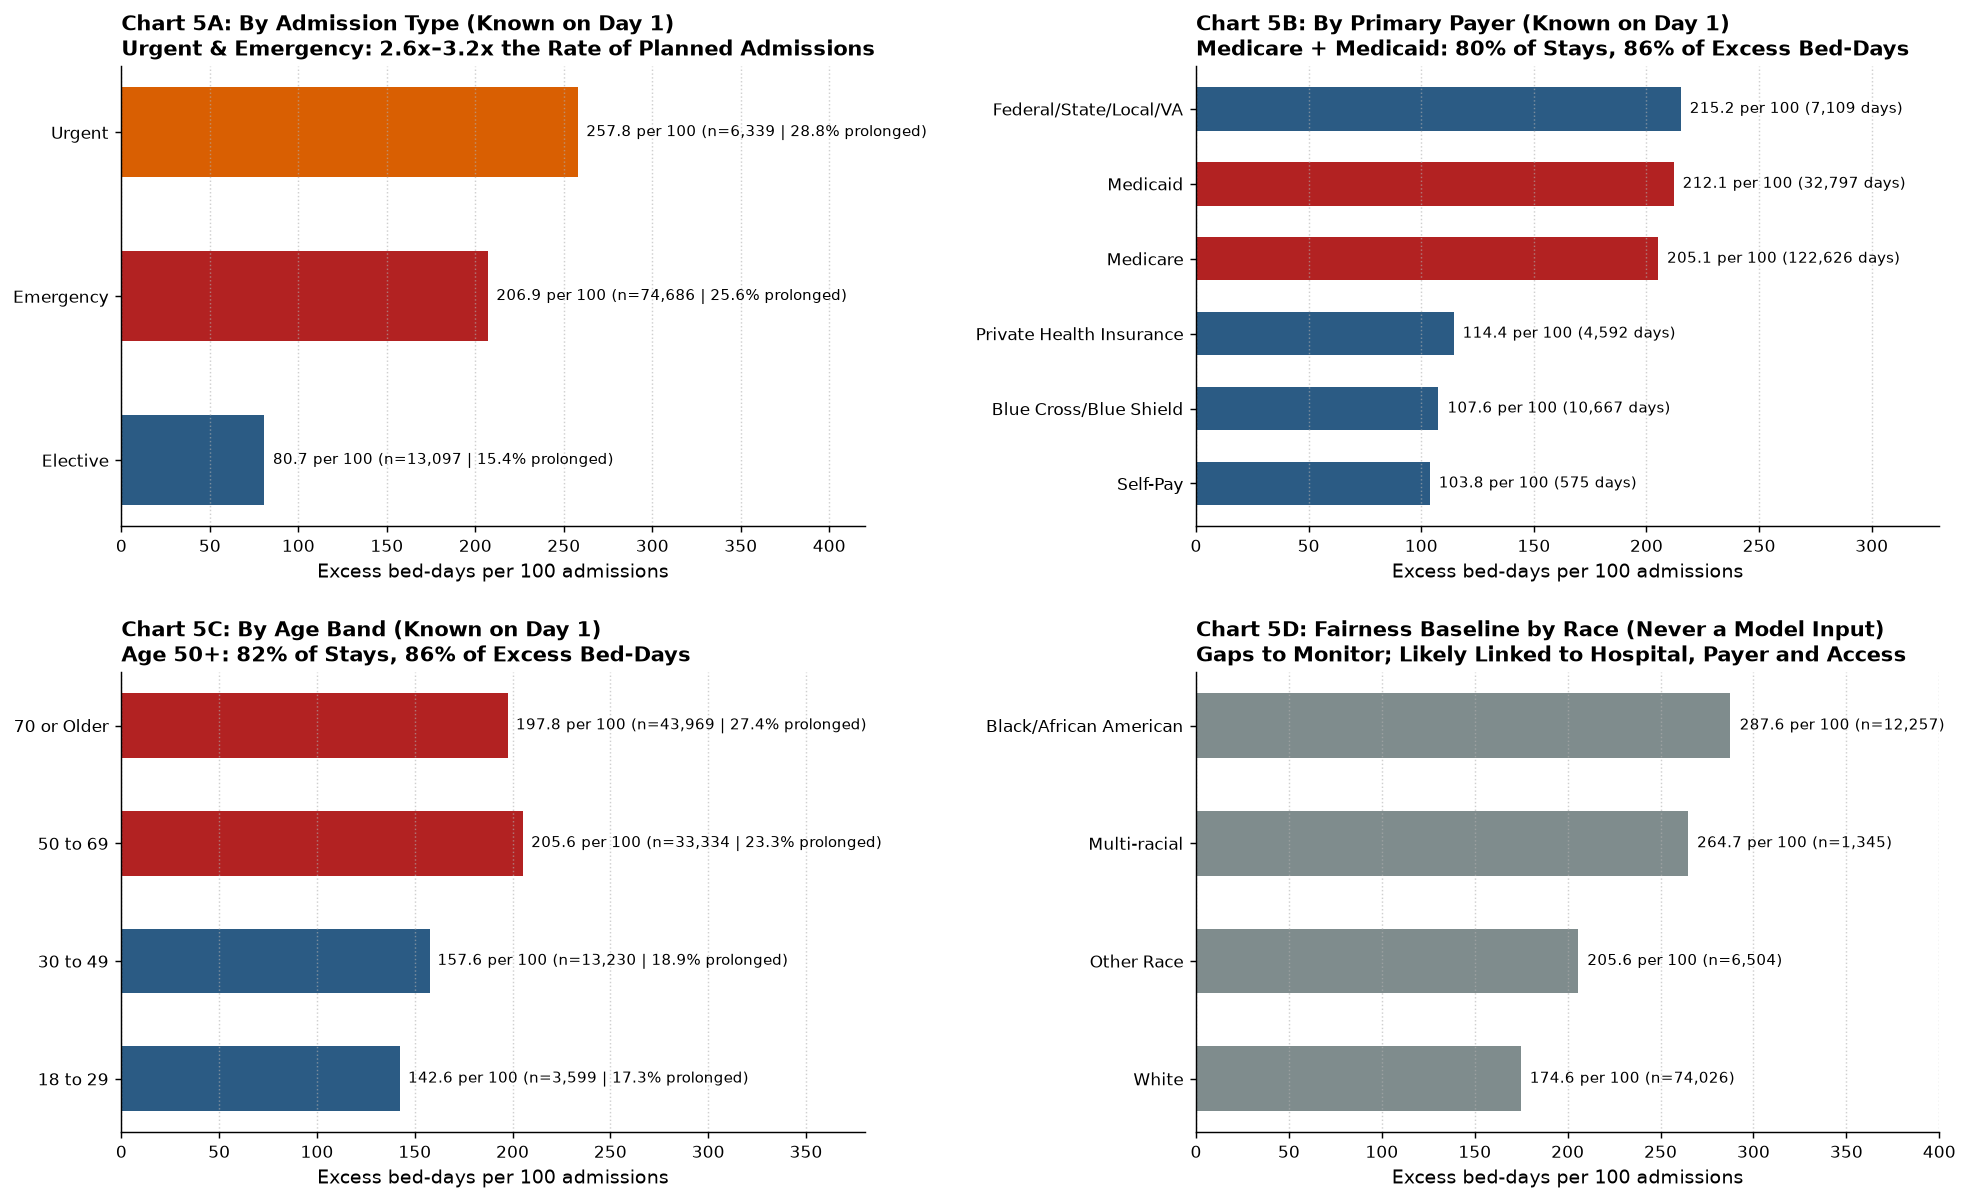

In [10]:
# ===== Chart 5: Day-1 signals and fairness baseline =====
def by(col, keep=None):
    d = fl23 if keep is None else fl23[fl23[col].isin(keep)]
    out = d.groupby(col, observed=True, as_index=False).agg(
        stays=("los", "count"), excess_days=("excess_days", "sum"), prolonged=("prolonged", "mean"))
    out["excess_per_100"] = 100 * out["excess_days"] / out["stays"]
    return out

adm_df = by("type_of_admission", ["Emergency", "Urgent", "Elective"])
pay_df = by("payment_typology_1", ["Medicare", "Medicaid", "Federal/State/Local/VA",
                                   "Private Health Insurance", "Blue Cross/Blue Shield", "Self-Pay"])
age_df = by("age_group")
race_df = by("race")

mm = fl23["payment_typology_1"].isin(["Medicare", "Medicaid"])
MM_STAY_SHARE = 100 * mm.mean()
MM_EXCESS_SHARE = 100 * fl23.loc[mm, "excess_days"].sum() / fl23["excess_days"].sum()
a50 = fl23["age_group"].isin(["50 to 69", "70 or Older"])
AGE50_STAY_SHARE = 100 * a50.mean()
AGE50_EXCESS_SHARE = 100 * fl23.loc[a50, "excess_days"].sum() / fl23["excess_days"].sum()
print(f"Medicare + Medicaid: {MM_STAY_SHARE:.1f}% of stays, {MM_EXCESS_SHARE:.1f}% of excess days")
print(f"Age 50+:             {AGE50_STAY_SHARE:.1f}% of stays, {AGE50_EXCESS_SHARE:.1f}% of excess days")

# ---- PLOT (uses only the aggregated tables above) ----
fig, axes = plt.subplots(2, 2, figsize=(15.5, 9.6))

a = adm_df.sort_values("excess_per_100", ascending=True)
b = axes[0, 0].barh(a["type_of_admission"].astype(str), a["excess_per_100"],
                    color=[PALETTE["ny"], PALETTE["fl"], PALETTE["amber"]], height=0.55)
for bar, (_, r) in zip(b, a.iterrows()):
    axes[0, 0].text(bar.get_width() + 5, bar.get_y() + bar.get_height() / 2,
                    f"{r['excess_per_100']:.1f} per 100 (n={r['stays']:,} | {100*r['prolonged']:.1f}% prolonged)", va="center", fontsize=8.5)
el = a.set_index("type_of_admission")["excess_per_100"]
axes[0, 0].set_title(f"Chart 5A: By Admission Type (Known on Day 1)\nUrgent & Emergency: "
                     f"{el['Emergency']/el['Elective']:.1f}x–{el['Urgent']/el['Elective']:.1f}x the Rate of Planned Admissions",
                     loc="left", fontsize=11.5)
axes[0, 0].set_xlabel("Excess bed-days per 100 admissions")
axes[0, 0].set_xlim(0, 420)
axes[0, 0].grid(axis="x", linestyle=":", alpha=0.6)

p = pay_df.sort_values("excess_per_100", ascending=True)
b = axes[0, 1].barh(p["payment_typology_1"].astype(str), p["excess_per_100"],
                    color=[PALETTE["fl"] if x in ("Medicare", "Medicaid") else PALETTE["ny"] for x in p["payment_typology_1"]], height=0.58)
for bar, (_, r) in zip(b, p.iterrows()):
    axes[0, 1].text(bar.get_width() + 4, bar.get_y() + bar.get_height() / 2,
                    f"{r['excess_per_100']:.1f} per 100 ({r['excess_days']:,.0f} days)", va="center", fontsize=8.5)
axes[0, 1].set_title(f"Chart 5B: By Primary Payer (Known on Day 1)\nMedicare + Medicaid: "
                     f"{MM_STAY_SHARE:.0f}% of Stays, {MM_EXCESS_SHARE:.0f}% of Excess Bed-Days", loc="left", fontsize=11.5)
axes[0, 1].set_xlabel("Excess bed-days per 100 admissions")
axes[0, 1].set_xlim(0, 330)
axes[0, 1].grid(axis="x", linestyle=":", alpha=0.6)

order = ["18 to 29", "30 to 49", "50 to 69", "70 or Older"]
g = age_df.set_index("age_group").reindex(order).reset_index()
b = axes[1, 0].barh(g["age_group"].astype(str), g["excess_per_100"],
                    color=[PALETTE["ny"], PALETTE["ny"], PALETTE["fl"], PALETTE["fl"]], height=0.55)
for bar, (_, r) in zip(b, g.iterrows()):
    axes[1, 0].text(bar.get_width() + 4, bar.get_y() + bar.get_height() / 2,
                    f"{r['excess_per_100']:.1f} per 100 (n={int(r['stays']):,} | {100*r['prolonged']:.1f}% prolonged)", va="center", fontsize=8.5)
axes[1, 0].set_title(f"Chart 5C: By Age Band (Known on Day 1)\nAge 50+: "
                     f"{AGE50_STAY_SHARE:.0f}% of Stays, {AGE50_EXCESS_SHARE:.0f}% of Excess Bed-Days", loc="left", fontsize=11.5)
axes[1, 0].set_xlabel("Excess bed-days per 100 admissions")
axes[1, 0].set_xlim(0, 380)
axes[1, 0].grid(axis="x", linestyle=":", alpha=0.6)

rc = race_df.sort_values("excess_per_100", ascending=True)
b = axes[1, 1].barh(rc["race"].astype(str), rc["excess_per_100"], color=PALETTE["grey"], height=0.55)
for bar, (_, r) in zip(b, rc.iterrows()):
    axes[1, 1].text(bar.get_width() + 5, bar.get_y() + bar.get_height() / 2,
                    f"{r['excess_per_100']:.1f} per 100 (n={r['stays']:,})", va="center", fontsize=8.5)
axes[1, 1].set_title("Chart 5D: Fairness Baseline by Race (Never a Model Input)\n"
                     "Gaps to Monitor; Likely Linked to Hospital, Payer and Access", loc="left", fontsize=11.5)
axes[1, 1].set_xlabel("Excess bed-days per 100 admissions")
axes[1, 1].set_xlim(0, 400)
axes[1, 1].grid(axis="x", linestyle=":", alpha=0.6)

plt.tight_layout(pad=2.0)
plt.savefig(FIG_DIR / "chart5_admission_signals_and_fairness.png", bbox_inches="tight")
plt.show()

---
## Step 7: The financial case (Task 5, Chart 6)

The reviewer asked for **(1) the cost of an excess bed-day, (2) the cost of early discharge planning and (3) the annual impact.** All inputs come from Finger Lakes 2023 data, except the four assumptions marked ▲.

### 1. What an excess bed-day is worth: two value streams
* **Full cost of a prolonged stay's day:** $2,344 (total costs ÷ bed-days of prolonged stays).
* **Cash saved ▲:** only the **variable** part of that cost disappears when a day is avoided. We use **16%** ([Roberts et al., JAMA 1999](https://jamanetwork.com/journals/jama/fullarticle/188795): 84% of hospital costs are fixed), so **$375 per day**, and test 30% and 45%.
* **Capacity ▲:** under per-case payment, a freed bed is worth more **refilled** than empty. An extra admission brings its payment (assumed ≈ the average cost of a stay, $18,777, as hospitals run close to break-even) minus its own variable cost: **$15,773 per admission**, or **$2,359 per refilled bed-day** (÷ 6.69-day average stay). How many freed beds are refilled depends on unmet demand (ED boarding, cancelled surgery), so we test **0–100%**.

### 2. What early discharge planning costs
* **▲ $200 per flagged patient** (about 3 hours of case manager or social worker time).
* We pay it for **every flagged patient**, including false alarms.

### 3. Annual impact
* **Programme:** flag 30% of admissions (**28,240 a year → $5.65M**).
* **▲ H1:** the flag catches **65% of prolonged stays** (14,914 caught, 13,326 false alarms; precision 53% vs. a 24.4% base rate).

| Scenario | Days saved per caught stay | Freed beds refilled | Beds freed daily | Cash | Capacity | **Net per year** |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| Conservative | 0.5 | 25% | 20 | $2.8M | $4.4M | **+$1.5M** |
| Base | 1.0 | 50% | 41 | $5.6M | $17.6M | **+$17.5M** |
| Optimistic | 1.5 | 75% | 61 | $8.4M | $39.6M | **+$42.3M** |

* **Break-even:** **1.0 day** per caught stay on cash alone; **0.39 day** with 25% refilled; **0.24 day** with 50% refilled (out of 7.9 excess days per prolonged stay).
* **Robust to the cost assumption:** with a 45% variable share the base case is +$21.6M instead of +$17.5M. What is not saved as cash comes back as capacity.
* **Cost of doing nothing:** the 79,700-day addressable gap is worth at least **$29.9M a year in cash alone**, plus the capacity for ~11,900 admissions.

=== FINGER LAKES 2023: INPUTS ===
  KPI-eligible admissions:              94,132
  Prolonged stays (LOS > P75):          22,944 (24.4%)
  Excess bed-days (total):             181,460 (7.91 per prolonged stay)
  Addressable gap (vs 2017 rate):       79,740 (218 beds/day, 11,925 admissions)
  Average stay / cost per stay:     6.69 d / $18,777
  Full cost per prolonged day:      $2,344
  Cash per bed-day saved (16%):     $375
  Capacity per refilled bed-day:    $2,359 ($15,773 per extra admission)
  Programme: 28,240 flagged x $200 = $5.65M (14,914 caught, 13,326 false alarms, precision 53%)
  Cost of doing nothing: gap worth >= $29.9M/yr in cash alone

=== ANNUAL SCENARIOS (FINGER LAKES, 16% VARIABLE COST) ===


,Scenario,Days saved per caught stay,Freed beds refilled,Bed-days saved,Beds freed daily,Extra admissions,Cash ($M),Capacity ($M),Programme ($M),Net ($M),Value per $1 spent,New KPI (per 100)
0,Conservative,0.5,0.25,7457.0,20.43,278.78,2.80,4.40,5.65,1.55,1.27,184.85
1,Base,1.0,0.50,14914.0,40.86,1115.14,5.59,17.59,5.65,17.53,4.10,176.93
2,Optimistic,1.5,0.75,22371.0,61.29,2509.06,8.39,39.57,5.65,42.32,8.49,169.01



Break-even days saved per caught stay:
  0% of freed beds refilled: 1.01 days
  25% of freed beds refilled: 0.39 days
  50% of freed beds refilled: 0.24 days

Base case under other variable-cost shares:
  16%: net $+17.5M
  30%: net $+19.5M
  45%: net $+21.6M


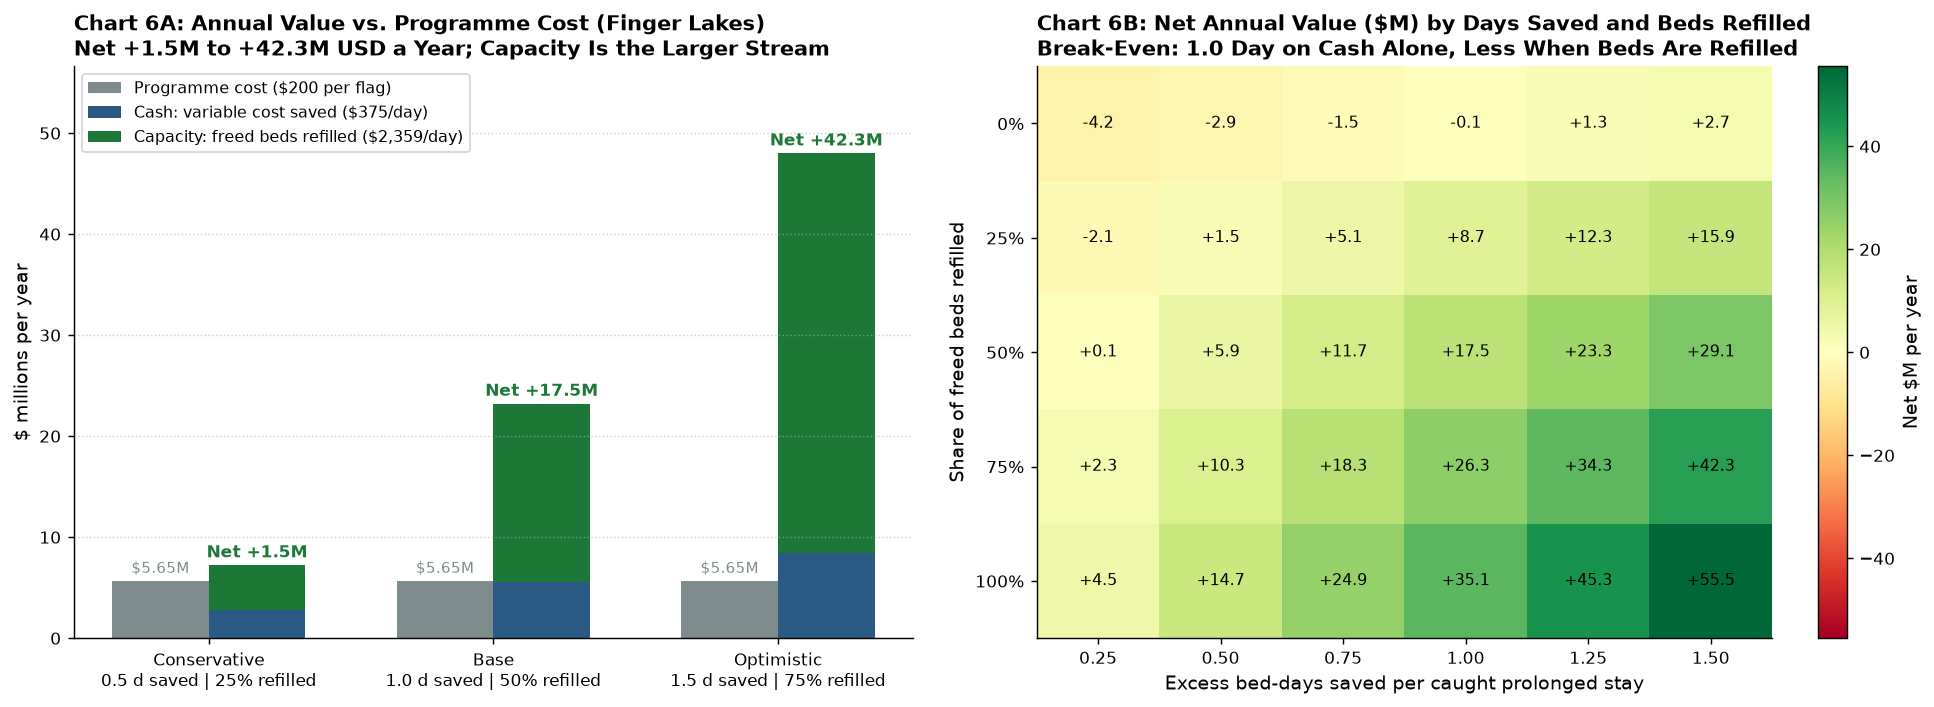

In [11]:
# ===== Chart 6: the financial case (cash + capacity) =====
# --- From the data (Finger Lakes 2023, KPI-eligible) ---
N_STAYS = len(fl23)
N_PROLONGED = int(fl23["prolonged"].sum())
TOT_EXCESS_DAYS = float(fl23["excess_days"].sum())
AVG_EXCESS_PER_PROLONGED = TOT_EXCESS_DAYS / N_PROLONGED
TOTAL_BED_DAYS = float(fl23["los"].sum())
ALOS = TOTAL_BED_DAYS / N_STAYS
AVG_COST_PER_STAY = fl23["total_costs"].sum() / N_STAYS
FULL_COST_PER_DAY_PROLONGED = (fl23.loc[fl23["prolonged"], "total_costs"].sum()
                               / fl23.loc[fl23["prolonged"], "los"].sum())

# --- Assumptions (▲ in the text) ---
VARIABLE_SHARE = 0.16   # Roberts et al., JAMA 1999: 84% of hospital costs are fixed; tested at 0.30 and 0.45
COST_PER_FLAG = 200.0   # ~3 h of case manager / social worker time per flagged patient
FLAG_RATE = 0.30        # share of admissions flagged on Day 1
TARGET_RECALL = 0.65    # H1: share of prolonged stays caught by the flag (to prove in WP3)
# Capacity: an extra admission pays ~ the average cost of a stay (hospitals run near break-even)
# and consumes its own variable cost, so its contribution = (1 - variable share) x average cost per stay.

def unit_values(v):
    cash = v * FULL_COST_PER_DAY_PROLONGED
    margin_per_adm = (1 - v) * AVG_COST_PER_STAY
    return cash, margin_per_adm, margin_per_adm / ALOS

CASH_PER_DAY, MARGIN_PER_ADM, CAP_PER_REFILLED_DAY = unit_values(VARIABLE_SHARE)
n_flagged = int(round(N_STAYS * FLAG_RATE))
tp = int(round(N_PROLONGED * TARGET_RECALL))
fp = n_flagged - tp
PROGRAM_COST = n_flagged * COST_PER_FLAG
GAP_CASH = GAP_23 * CASH_PER_DAY

print("=== FINGER LAKES 2023: INPUTS ===")
print(f"  KPI-eligible admissions:          {N_STAYS:>10,}")
print(f"  Prolonged stays (LOS > P75):      {N_PROLONGED:>10,} ({100*N_PROLONGED/N_STAYS:.1f}%)")
print(f"  Excess bed-days (total):          {TOT_EXCESS_DAYS:>10,.0f} ({AVG_EXCESS_PER_PROLONGED:.2f} per prolonged stay)")
print(f"  Addressable gap (vs 2017 rate):   {GAP_23:>10,.0f} ({GAP_23/365:.0f} beds/day, {GAP_23/ALOS:,.0f} admissions)")
print(f"  Average stay / cost per stay:     {ALOS:.2f} d / ${AVG_COST_PER_STAY:,.0f}")
print(f"  Full cost per prolonged day:      ${FULL_COST_PER_DAY_PROLONGED:,.0f}")
print(f"  Cash per bed-day saved ({VARIABLE_SHARE:.0%}):     ${CASH_PER_DAY:,.0f}")
print(f"  Capacity per refilled bed-day:    ${CAP_PER_REFILLED_DAY:,.0f} (${MARGIN_PER_ADM:,.0f} per extra admission)")
print(f"  Programme: {n_flagged:,} flagged x ${COST_PER_FLAG:.0f} = ${PROGRAM_COST/1e6:.2f}M "
      f"({tp:,} caught, {fp:,} false alarms, precision {tp/n_flagged:.0%})")
print(f"  Cost of doing nothing: gap worth >= ${GAP_CASH/1e6:.1f}M/yr in cash alone")

rows = []
for name, days_saved, refill in [("Conservative", 0.5, 0.25), ("Base", 1.0, 0.50), ("Optimistic", 1.5, 0.75)]:
    bed_days = tp * days_saved
    cash = bed_days * CASH_PER_DAY
    capacity = bed_days * refill * CAP_PER_REFILLED_DAY
    rows.append({"Scenario": name, "Days saved per caught stay": days_saved, "Freed beds refilled": refill,
                 "Bed-days saved": bed_days, "Beds freed daily": bed_days / 365,
                 "Extra admissions": bed_days * refill / ALOS,
                 "Cash ($M)": cash / 1e6, "Capacity ($M)": capacity / 1e6, "Programme ($M)": PROGRAM_COST / 1e6,
                 "Net ($M)": (cash + capacity - PROGRAM_COST) / 1e6,
                 "Value per $1 spent": (cash + capacity) / PROGRAM_COST,
                 "New KPI (per 100)": 100 * (TOT_EXCESS_DAYS - bed_days) / N_STAYS})
scen_df = pd.DataFrame(rows)
print("\n=== ANNUAL SCENARIOS (FINGER LAKES, 16% VARIABLE COST) ===")
display(scen_df.round(2))

print("\nBreak-even days saved per caught stay:")
for r_ in (0.0, 0.25, 0.5):
    print(f"  {r_:.0%} of freed beds refilled: {PROGRAM_COST / (tp * (CASH_PER_DAY + r_ * CAP_PER_REFILLED_DAY)):.2f} days")
print("\nBase case under other variable-cost shares:")
for v in (0.16, 0.30, 0.45):
    c, _, cap = unit_values(v)
    print(f"  {v:.0%}: net ${(tp * 1.0 * (c + 0.5 * cap) - PROGRAM_COST)/1e6:+.1f}M")

days_grid = [0.25, 0.50, 0.75, 1.00, 1.25, 1.50]
refill_grid = [0.0, 0.25, 0.50, 0.75, 1.00]
heat = np.array([[(tp * d * (CASH_PER_DAY + r_ * CAP_PER_REFILLED_DAY) - PROGRAM_COST) / 1e6
                  for d in days_grid] for r_ in refill_grid])

# ---- PLOT (uses only the aggregated tables above) ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 5.8), gridspec_kw={"width_ratios": [1.05, 1.15]})

x = np.arange(len(scen_df))
w = 0.34
ax1.bar(x - w / 2, scen_df["Programme ($M)"], width=w, color=PALETTE["grey"], label="Programme cost ($200 per flag)")
ax1.bar(x + w / 2, scen_df["Cash ($M)"], width=w, color=PALETTE["ny"], label=f"Cash: variable cost saved (${CASH_PER_DAY:,.0f}/day)")
ax1.bar(x + w / 2, scen_df["Capacity ($M)"], width=w, bottom=scen_df["Cash ($M)"], color=PALETTE["teal"],
        label=f"Capacity: freed beds refilled (${CAP_PER_REFILLED_DAY:,.0f}/day)")
for i, r in scen_df.iterrows():
    ax1.text(i - w / 2, r["Programme ($M)"] + 0.8, f"${r['Programme ($M)']:.2f}M", ha="center", fontsize=8.5, color=PALETTE["grey"])
    top_ = r["Cash ($M)"] + r["Capacity ($M)"]
    ax1.text(i + w / 2, top_ + 0.8, f"Net {r['Net ($M)']:+.1f}M", ha="center", fontsize=9.5, fontweight="bold", color=PALETTE["teal"])
ax1.set_xticks(x)
ax1.set_xticklabels([f"{r['Scenario']}\n{r['Days saved per caught stay']:.1f} d saved | {r['Freed beds refilled']:.0%} refilled"
                     for _, r in scen_df.iterrows()])
ax1.set_title("Chart 6A: Annual Value vs. Programme Cost (Finger Lakes)\n"
              f"Net {scen_df['Net ($M)'].iloc[0]:+.1f}M to {scen_df['Net ($M)'].iloc[-1]:+.1f}M USD a Year; Capacity Is the Larger Stream",
              loc="left", fontsize=11.5)
ax1.set_ylabel("$ millions per year")
ax1.set_ylim(0, (scen_df["Cash ($M)"] + scen_df["Capacity ($M)"]).max() * 1.18)
ax1.grid(axis="y", linestyle=":", alpha=0.6)
ax1.legend(loc="upper left", frameon=True, fontsize=9)

im = ax2.imshow(heat, cmap="RdYlGn", vmin=-abs(heat).max(), vmax=abs(heat).max(), aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax2.text(j, i, f"{heat[i, j]:+.1f}", ha="center", va="center", fontsize=9)
ax2.set_xticks(range(len(days_grid)))
ax2.set_xticklabels([f"{d:.2f}" for d in days_grid])
ax2.set_yticks(range(len(refill_grid)))
ax2.set_yticklabels([f"{r_:.0%}" for r_ in refill_grid])
ax2.set_xlabel("Excess bed-days saved per caught prolonged stay")
ax2.set_ylabel("Share of freed beds refilled")
be_cash = PROGRAM_COST / (tp * CASH_PER_DAY)
ax2.set_title(f"Chart 6B: Net Annual Value ($M) by Days Saved and Beds Refilled\n"
              f"Break-Even: {be_cash:.1f} Day on Cash Alone, Less When Beds Are Refilled", loc="left", fontsize=11.5)
fig.colorbar(im, ax=ax2, label="Net $M per year")

plt.tight_layout(pad=2.0)
plt.savefig(FIG_DIR / "chart6_cost_scenario_and_roi_matrix.png", bbox_inches="tight")
plt.show()

---
## Step 8: The 8 WP1 requirements at a glance (ready for slides)

| Requirement | Answer for the board | Key numbers |
| :--- | :--- | :--- |
| **1. Case & context** | Finger Lakes Health System (17 hospitals, Rochester, NY). Paid per admission (DRG), so excess days bring no revenue, cost money and block beds. | 137,867 raw stays (2023) → 99,880 adult medical-surgical → **94,132 KPI-eligible** |
| **2. Decision & owner** | **At admission**, flag likely overstays so case managers start arranging post-hospital care on Day 1. Owners: **Director of Patient Flow** and **Head of Case Management**. | Flag 30% = **28,240 a year (~77 a day)**; start in the 4 Rochester hospitals (76% of stays, 89% of excess days) |
| **3. KPI & baseline** | **Excess bed-days per 100 admissions** vs. the frozen 2017 statewide P75 for the same diagnosis and severity. | **2023: 192.8** (181,460 days; 24.4% prolonged; average stay 6.69 days) |
| **4. Executive EDA** | (1) +78% since 2017, highest region in NY; (2) post-hospital care = 41% of stays, 74.8% of excess days; (3) 4 hospitals = 89%; (4) 30 conditions = 53%. | SNF: 515 excess days per 100 stays (6.6× home) |
| **5. Expected value vs. doing nothing** | Doing nothing: an **addressable gap of 79,700 bed-days a year (218 beds daily)**, at least $29.9M a year in cash plus lost capacity. Acting: $200 per flag vs. $375 cash + $2,359 capacity per refilled bed-day. | Programme $5.65M a year. Net: **+$1.5M / +$17.5M / +$42.3M**. Break-even 1.0 day (cash only) or 0.24 day (50% refilled) |
| **6. Data sources & gaps** | NY SPARCS, de-identified at source (no consent needed). Missing: patient id (no readmissions), dates and ward census, provisional diagnosis, social factors. | 6.23M stays (2017, 2018, 2019, 2023) + trend counts 2016–2021, 2023 |
| **7. Hypotheses (to prove)** | **H1:** Day-1 data catches ≥65% of prolonged stays while flagging 30%. **H2:** the need for post-hospital care can be predicted on Day 1. **H3:** hospital differences remain after more patient-mix controls (process, not patients). **H4:** early planning saves more than break-even per caught stay (WP4 pilot). | Break-even: 1.0 day (cash) / 0.24 day (50% refilled) of 7.9 excess days per prolonged stay |
| **8. Delivery & lifecycle** | **07:00 daily risk list** in the EHR case-management worklist. **Ruler frozen** for the life of the project; the **model** is retrained each year with the new SPARCS release or when drift is detected. Monthly: KPI vs. baseline, flag precision and recall, fairness by payer and race. | Fairness baseline: 287.6 (Black) vs. 174.6 (White) excess days per 100, monitored, not a model input |